In [1]:
import pandas as pd, numpy as np, os, json, time, warnings
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.metrics import adjusted_rand_score
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid')
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 60)

# ---- settings you may change ----
PRED_FILE = None          # None = auto-detect pair_predictions.csv or pair_scores.csv
SCORE_COL = None          # None = auto-detect (proba / score / prob ...)
THRESHOLD = None          # None = pick the best threshold from the sweep; or set e.g. 0.5
MAX_SIZE  = 4             # largest plausible number of records for one customer (EDA showed 4)

if PRED_FILE is None:
    PRED_FILE = next(f for f in ['pair_predictions.csv', 'pair_scores.csv'] if os.path.exists(f))
pred = pd.read_csv(PRED_FILE)
if SCORE_COL is None:
    SCORE_COL = next((c for c in ['proba', 'score', 'prob', 'probability', 'y_prob'] if c in pred.columns), None)
    if SCORE_COL is None:   # fall back: first column that looks like a probability
        SCORE_COL = next(c for c in pred.columns if c not in ('idx_a','idx_b','label','pred') and pred[c].dtype.kind == 'f' and pred[c].between(0, 1).all())
print('prediction file:', PRED_FILE, '| score column:', SCORE_COL, '| pairs:', len(pred))

cust = pd.read_csv('cleaned_customers.csv', low_memory=False, keep_default_na=False, na_values=[''],
                   dtype={'zip_code': str, 'phone_c': str})
n = len(cust); print('records:', n)
ia, ib, score = pred.idx_a.values, pred.idx_b.values, pred[SCORE_COL].values
true_codes, _ = pd.factorize(cust.true_customer_id)       # evaluation only
print('true customers:', true_codes.max() + 1)

prediction file: pair_predictions.csv | score column: proba | pairs: 784350
records: 185000
true customers: 90000


## 1. Pair-level quality of the classifier (reminder)
These numbers only count the candidate pairs, not groups.

In [2]:
pair_true = (true_codes[ia] == true_codes[ib])
def pair_level(thr):
    p = score >= thr
    tp = (p & pair_true).sum()
    return dict(threshold=thr, pairs_called_same=int(p.sum()), precision=tp/max(p.sum(),1), recall=tp/pair_true.sum(), F1=2*tp/(p.sum()+pair_true.sum()))
pd.DataFrame([pair_level(t) for t in [0.3, 0.5, 0.7, 0.9, 0.99]]).round(4)

,threshold,pairs_called_same,precision,recall,F1
0,0.30,118153,0.9981,0.9995,0.9988
1,0.50,117995,0.9990,0.9991,0.9990
2,0.70,117922,0.9992,0.9987,0.9989
3,0.90,117647,0.9996,0.9967,0.9981
4,0.99,116166,0.9999,0.9845,0.9921


## 2. Connected components
`connected_components` walks the graph and gives every record a group number. Records with no "same" edge stay alone (a group of size 1).

In [3]:
def cluster(threshold):
    m = score >= threshold
    g = coo_matrix((np.ones(m.sum(), dtype=np.int8), (ia[m], ib[m])), shape=(n, n))
    k, labels = connected_components(g, directed=False)
    return labels

def pairs_of(x): return int((x * (x - 1) // 2).sum())
def eval_clusters(labels):
    sizes = np.bincount(labels)
    key = labels.astype(np.int64) * (true_codes.max() + 1) + true_codes
    tp = pairs_of(np.unique(key, return_counts=True)[1])
    pp, tt = pairs_of(sizes), pairs_of(np.bincount(true_codes))
    frame = pd.DataFrame({'c': labels, 't': true_codes})
    impure = int((frame.groupby('c').t.nunique() > 1).sum())          # groups that contain several real customers
    split = int((frame.groupby('t').c.nunique() > 1).sum())           # real customers spread over several groups
    return dict(groups=int(len(sizes)), singletons=int((sizes == 1).sum()), max_size=int(sizes.max()),
                precision=tp/max(pp,1), recall=tp/tt, F1=2*tp/(pp+tt), ARI=adjusted_rand_score(true_codes, labels),
                impure_groups=impure, split_customers=split)

rows = []
for t in [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99, 0.999]:
    rows.append({'threshold': t, **eval_clusters(cluster(t))})
sweep = pd.DataFrame(rows)
print('Group-level quality (pairs of records inside groups), true customers =', true_codes.max() + 1)
sweep.round(4)

Group-level quality (pairs of records inside groups), true customers = 90000


,threshold,groups,singletons,max_size,precision,recall,F1,ARI,impure_groups,split_customers
0,0.100,89754,16602,35,0.9801,0.9992,0.9896,0.9896,251,55
1,0.300,89894,16623,31,0.9895,0.9992,0.9943,0.9943,140,58
2,0.500,89996,16679,8,0.9965,0.9990,0.9977,0.9977,79,80
3,0.700,90030,16704,8,0.9974,0.9988,0.9981,0.9981,61,94
4,0.900,90115,16809,8,0.9984,0.9981,0.9983,0.9983,37,153
5,0.950,90339,17149,8,0.9991,0.9956,0.9973,0.9973,19,359
6,0.990,90854,17913,6,0.9996,0.9891,0.9943,0.9943,8,858
7,0.999,92953,21135,5,0.9999,0.9624,0.9808,0.9808,1,2925


threshold used: 0.9


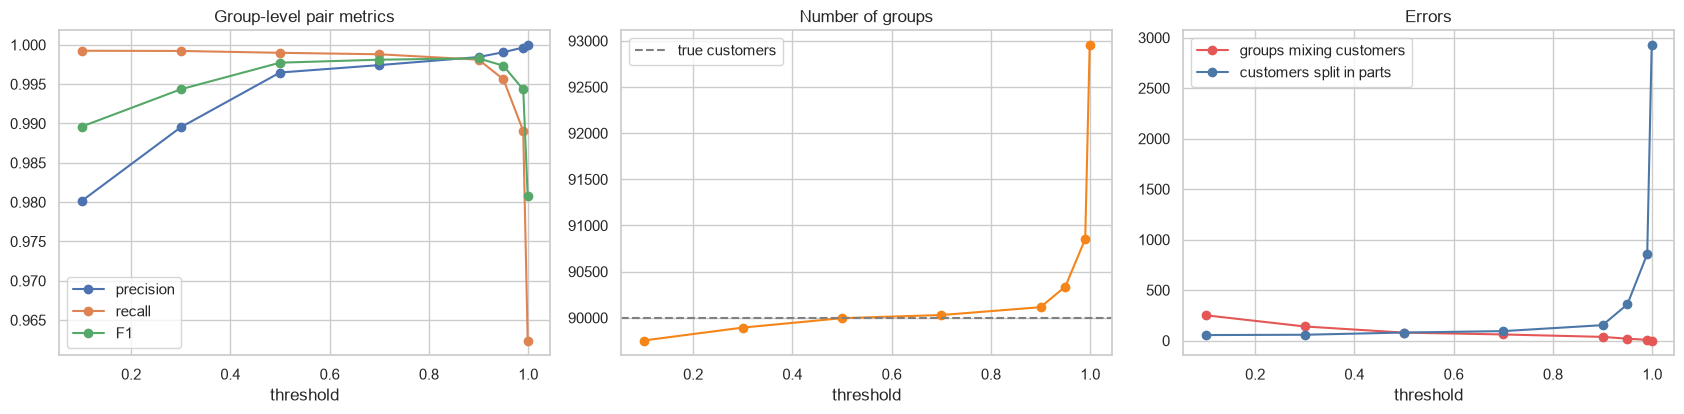

In [4]:
BEST = float(sweep.loc[sweep.F1.idxmax(), 'threshold']) if THRESHOLD is None else THRESHOLD
print('threshold used:', BEST)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
ax[0].plot(sweep.threshold, sweep.precision, marker='o', label='precision'); ax[0].plot(sweep.threshold, sweep.recall, marker='o', label='recall')
ax[0].plot(sweep.threshold, sweep.F1, marker='o', label='F1'); ax[0].set_xlabel('threshold'); ax[0].set_title('Group-level pair metrics'); ax[0].legend()
ax[1].plot(sweep.threshold, sweep.groups, marker='o', color='#F58518'); ax[1].axhline(true_codes.max()+1, color='grey', ls='--', label='true customers')
ax[1].set_xlabel('threshold'); ax[1].set_title('Number of groups'); ax[1].legend()
ax[2].plot(sweep.threshold, sweep.impure_groups, marker='o', color='#E45756', label='groups mixing customers')
ax[2].plot(sweep.threshold, sweep.split_customers, marker='o', color='#4C78A8', label='customers split in parts')
ax[2].set_xlabel('threshold'); ax[2].set_title('Errors'); ax[2].legend()
plt.tight_layout(); plt.show()

## 3. Refinement: split oversized groups
A group bigger than `MAX_SIZE` is suspicious (probably several customers chained together by one weak link). For those groups only, we keep raising the threshold until the pieces are small enough.

In [5]:
def refine(labels, base_thr, max_size, steps=(0.9, 0.95, 0.98, 0.99, 0.995, 0.999)):
    labels = labels.copy()
    for t in steps:
        if t <= base_thr: continue
        big = np.bincount(labels)[labels] > max_size
        if not big.any(): break
        m = big[ia] & big[ib] & (labels[ia] == labels[ib]) & (score >= t)
        g = coo_matrix((np.ones(m.sum(), dtype=np.int8), (ia[m], ib[m])), shape=(n, n))
        _, sub = connected_components(g, directed=False)
        nodes = np.where(big)[0]
        labels[nodes] = labels.max() + 1 + sub[nodes]
        _, labels = np.unique(labels, return_inverse=True)
    return labels

lab0 = cluster(BEST); lab1 = refine(lab0, BEST, MAX_SIZE)
cmp = pd.DataFrame({'plain components': eval_clusters(lab0), f'refined (max size {MAX_SIZE})': eval_clusters(lab1)}).T
print('groups bigger than MAX_SIZE: before =', int((np.bincount(lab0) > MAX_SIZE).sum()), '| after =', int((np.bincount(lab1) > MAX_SIZE).sum()))
cmp.round(4)

groups bigger than MAX_SIZE: before = 15 | after = 1


,groups,singletons,max_size,precision,recall,F1,ARI,impure_groups,split_customers
plain components,90115.0,16809.0,8.0,0.9984,0.9981,0.9983,0.9983,37.0,153.0
refined (max size 4),90135.0,16815.0,5.0,0.9993,0.9980,0.9987,0.9987,25.0,159.0


In [6]:
final = lab1
sizes = pd.Series(np.bincount(final)).value_counts().sort_index()
print('Group size distribution (records per group):'); print(sizes.rename('groups').to_frame())
print('True distribution:'); print(pd.Series(np.bincount(true_codes)).value_counts().sort_index().rename('customers').to_frame())

fr = pd.DataFrame({'g': final, 't': true_codes})
gs = fr.groupby('g').agg(size=('t', 'size'), true_ids=('t', 'nunique'))
ts = fr.groupby('t').agg(size=('g', 'size'), parts=('g', 'nunique'))
exact = (gs.true_ids == 1).sum() - 0
perfect = fr.merge(gs, left_on='g', right_index=True).merge(ts, left_on='t', right_index=True, suffixes=('_g', '_t'))
perfect = perfect[(perfect.true_ids == 1) & (perfect.parts == 1)].t.nunique()
print(f'\nCustomers recovered EXACTLY (all their records together and nobody else): {perfect:,} of {true_codes.max()+1:,} ({perfect/(true_codes.max()+1):.2%})')

Group size distribution (records per group):
   groups
1   16815
2   53325
3   18446
4    1548
5       1
True distribution:
   customers
1      16577
2      53385
3      18499
4       1539

Customers recovered EXACTLY (all their records together and nobody else): 89,794 of 90,000 (99.77%)


## 4. Look at the errors

In [7]:
show = ['record_id', 'full_name', 'email', 'phone', 'address', 'source_system', 'true_customer_id']
bad = gs[gs.true_ids > 1].sort_values('size', ascending=False).head(3).index
print('GROUPS THAT MIX DIFFERENT CUSTOMERS (wrong merges):' if len(bad) else 'No group mixes different customers.')
for g in bad: display(cust.loc[final == g, show])
split_t = ts[ts.parts > 1].sort_values('size', ascending=False).head(3).index
print('CUSTOMERS SPLIT INTO SEVERAL GROUPS (missed links):' if len(split_t) else 'No customer is split.')
for t in split_t: display(cust.loc[true_codes == t, show].assign(group=final[true_codes == t]))

GROUPS THAT MIX DIFFERENT CUSTOMERS (wrong merges):


,record_id,full_name,email,phone,address,source_system,true_customer_id
24912,CRM0024913,James Albright,jamesalbright89@example.org,3365125424,232 S Marshall Street,CRM,CUST037226
62677,CRM0062678,James M. Albright,jamesalbright89@example.org,(336) 512-5424,232 S Marshall St,CRM,CUST037226
79349,CRM0079350,James Albright,james.albright89@post.example,(336) 684-7713,4622 Preacher Holmes Rd #A,CRM,CUST050006
137320,BIL0037321,ALBRIGHT JAMES,james.albright89@post.example,NaN,4622 Preacher Holmse Rd #A,BILLING,CUST050006
142306,BIL0042307,ALBRIGHT JIM,jamesalbright89@example.net,3365125424,NaN,BILLING,CUST037226


,record_id,full_name,email,phone,address,source_system,true_customer_id
10108,CRM0010109,Rosalia I. Hernandez Rodriguez,rhernandezrodriguez26@example.org,(336) 675-4402,1930 Morrow School Rd,CRM,CUST035641
99378,CRM0099379,Rosa Hernandez Rodriguez,rhernandezrodriguez9@example.com,NaN,1930 Morrow School Rd,CRM,CUST032842
122900,BIL0022901,"Hernandez Rodriguez, Rosalia",NaN,336-675-4402,1930 Morrow School Road,BILLING,CUST035641
152095,BIL0052096,Rosa Hernandez Rodriguez,rhernandezrodriguez9@example.com,NaN,1930 Morrow School Rd,BILLING,CUST032842


,record_id,full_name,email,phone,address,source_system,true_customer_id
10435,CRM0010436,Caeden Carriker,caeden.carriker86@inbox.example,(336) 437-2739,4503 Salem Church Rd,CRM,CUST061869
87509,CRM0087510,Charlene Carriker,charlene.carriker40@example.com,(336) 376-9528,4503 Salem Church Rd,CRM,CUST071719
119824,BIL0019825,C. Carriker,NaN,NaN,4503 Salem Church Road,BILLING,CUST071719
148763,BIL0048764,Caeden Carriker,caeden.carriker86@inbox.example,(336) 437-2739,4503 Salem Church Rd,BILLING,CUST061869


CUSTOMERS SPLIT INTO SEVERAL GROUPS (missed links):


,record_id,full_name,email,phone,address,source_system,true_customer_id,group
3456,CRM0003457,Kenneth B. Sthbbs,kenneth_stubbs55@example.com,NaN,2171 Hawthorne Ln,CRM,CUST009028,3444
34574,CRM0034575,Kenneth Stubbs,kenneth_stubbs55@example.com,NaN,2171 Hawthorne Ln,CRM,CUST009028,3444
140887,BIL0040888,"Subbs, Kenneth",kennath_stubbs55@example.com,NaN,NaN,BILLING,CUST009028,87130
167492,BIL0067493,K. Stubs,kenneth_stubbbs55@example.com,NaN,2171 Hawthrne Ln,BILLING,CUST009028,3444


,record_id,full_name,email,phone,address,source_system,true_customer_id,group
4740,CRM0004741,John H. Oakes,john.oakes69@inbox.example,(772) 480-1907,2266 Glenkirk Dr,CRM,CUST088057,4715
94615,CRM0094616,Jonh Oakes,john.oaes69@inbox.example,772-480-1907,2266 Glenkirk Drive,CRM,CUST088057,4715
109668,BIL0009669,John Oakes,john.oakes69@inbox.example,(772) 480-1907,2266 Glenkirk Dr,BILLING,CUST088057,4715
180254,BIL0080255,"Oakse, John",jkhn.oakes69@inbox.example,NaN,2266 GlenkirkpDr,BILLING,CUST088057,89795


,record_id,full_name,email,phone,address,source_system,true_customer_id,group
12995,CRM0012996,Donna Price,dprice29@example.org,NaN,338 Chapel Hill Rd #B,CRM,CUST049594,12744
37110,CRM0037111,Donna Price,dprice29@example.org,NaN,338 Chapel Hill Rd #B,CRM,CUST049594,12744
162277,BIL0062278,Donna Price,dprice29@example.org,NaN,338 Chapel Hill Rd #B,BILLING,CUST049594,12744
171752,BIL0071753,PRICE DONNA,dpriceu9@example.org,NaN,338 Chapel Hill Rd #B,BILLING,CUST049594,89237


## 5. Golden record: survivorship rules
For each group we create **one** record. Rules:

| Field | Rule |
|---|---|
| name | best-looking name: prefer `First Last` over `Last, First`, over UPPERCASE, over initials; then CRM before Billing; then longest |
| email, phone, zip, city | most frequent value in the group; ties go to CRM |
| address | most frequent; ties go to CRM (CRM addresses are written in the standard way) |
| created_date | earliest date among CRM records |
| customer_status | `Active` if any CRM record is active |
| invoice_count, total_billed | **sum** over Billing records (assumption: every Billing record is a separate account; change if they are copies) |
| last_invoice_date | latest; payment_method taken from that latest invoice |
| source_record_ids, n_records | list of merged record ids and their count |

In [8]:
c = cust.copy(); c['cid'] = final
c['prio'] = (c.source_system != 'CRM').astype(int)                       # CRM first
c['created_dt'] = pd.to_datetime(c.created_date, errors='coerce')
c['last_inv_dt'] = pd.to_datetime(c.last_invoice_date, errors='coerce')
name = c.full_name.fillna('')
c['name_q'] = (~name.str.contains(',')).astype(int) + (~name.str.isupper()).astype(int) + (~name.str.match(r'^[A-Z]\.\s')).astype(int)

def top_value(col):
    t = c[['cid', 'prio', col]].dropna(subset=[col])
    cnt = t.groupby(['cid', col]).agg(n=('prio', 'size'), prio=('prio', 'min')).reset_index()
    cnt = cnt.sort_values(['cid', 'n', 'prio'], ascending=[True, False, True]).drop_duplicates('cid')
    return cnt.set_index('cid')[col]

t0 = time.time()
gold = pd.DataFrame(index=pd.RangeIndex(final.max() + 1, name='cluster_id'))
best_name = c.assign(L=name.str.len()).sort_values(['cid', 'name_q', 'prio', 'L'], ascending=[True, False, True, False]).drop_duplicates('cid').set_index('cid').full_name
gold['full_name'] = best_name
for col in ['email', 'phone_c', 'address', 'zip_code', 'city']: gold[col] = top_value(col)
gold['phone'] = gold.phone_c.map(lambda p: f'({p[:3]}) {p[3:6]}-{p[6:]}' if isinstance(p, str) and len(p) == 10 else np.nan)
gold = gold.drop(columns='phone_c')

crm = c[c.source_system == 'CRM']; bil = c[c.source_system != 'CRM']
gold['created_date'] = crm.groupby('cid').created_dt.min().dt.date
gold['customer_status'] = crm.groupby('cid').customer_status.agg(lambda s: 'Active' if (s == 'Active').any() else 'Inactive')
gold['n_billing_records'] = bil.groupby('cid').size()
gold['invoice_count'] = bil.groupby('cid').invoice_count.sum(min_count=1)
gold['total_billed'] = bil.groupby('cid').total_billed.sum(min_count=1)
gold['last_invoice_date'] = bil.groupby('cid').last_inv_dt.max().dt.date
gold['payment_method'] = bil.sort_values('last_inv_dt').drop_duplicates('cid', keep='last').set_index('cid').payment_method
gold['n_records'] = c.groupby('cid').size()
gold['sources'] = c.groupby('cid').source_system.agg(lambda s: '+'.join(sorted(set(s))))
gold['source_record_ids'] = c.groupby('cid').record_id.agg(' | '.join)
gold['n_billing_records'] = gold.n_billing_records.fillna(0).astype(int)
print(f'golden records built in {time.time()-t0:.0f}s | {len(c):,} records -> {len(gold):,} customers')
gold.head()

golden records built in 29s | 185,000 records -> 90,135 customers


,full_name,email,address,zip_code,city,phone,created_date,customer_status,n_billing_records,invoice_count,total_billed,last_invoice_date,payment_method,n_records,sources,source_record_ids
cluster_id,,,,,,,,,,,,,,,,
0,Nathan Nance,nnance17@example.com,1142 Noah Rd,27253,Graham,NaN,2012-01-11,Active,1,40.0,8733.77,2026-09-27,Bank Transfer,3,BILLING+CRM,CRM0000001 | CRM0049179 | BIL0046754
1,Jonathan L. Henson,jonathan.henson3@mail.example,4881 Grosbeak Ct,27302,Mebane,NaN,2025-07-18,Active,1,23.0,17695.36,2025-12-23,Direct Debit,2,BILLING+CRM,CRM0000002 | BIL0074874
2,Dylan H. Wilkerson,dylan_wilkerson70@example.org,5609 Herring Hillside Dr,27253,Graham,(336) 212-8627,2017-12-28,Inactive,0,NaN,NaN,NaN,NaN,1,CRM,CRM0000003
3,Frankie King,frankie_king39@post.example,1452 Gant Rd,27253,Graham,NaN,2016-09-19,Active,2,81.0,25923.18,2026-06-23,Bank Transfer,3,BILLING+CRM,CRM0000004 | BIL0001656 | BIL0015662
4,Fellecia Cromity,felecia.cromity6@example.com,1315 Lansdowne Dr,27302,Mebane,NaN,2024-09-09,Active,1,19.0,22893.59,2026-07-20,Direct Debit,3,BILLING+CRM,CRM0000005 | CRM0063226 | BIL0012297


In [9]:
multi = gold[gold.n_records >= 3].head(4).index
for g in multi:
    print(f'--- group {g}: source records -> golden record')
    display(c.loc[c.cid == g, ['record_id', 'source_system', 'full_name', 'email', 'phone', 'address']])
    display(gold.loc[[g], ['full_name', 'email', 'phone', 'address', 'created_date', 'customer_status', 'invoice_count', 'total_billed', 'payment_method', 'n_records']])
print('Missing values in golden records (%):'); (gold[['full_name','email','phone','address']].isna().mean()*100).round(2)

--- group 0: source records -> golden record


,record_id,source_system,full_name,email,phone,address
0,CRM0000001,CRM,Nathan Nance,nnance17@example.com,NaN,1142 Noah Road
49178,CRM0049179,CRM,Nathan Nance,nnance17@example.com,NaN,1142 Noah Rd
146753,BIL0046754,BILLING,Nathan Nance,nnance17@example.com,NaN,1142 Noah Rd


,full_name,email,phone,address,created_date,customer_status,invoice_count,total_billed,payment_method,n_records
cluster_id,,,,,,,,,,
0,Nathan Nance,nnance17@example.com,NaN,1142 Noah Rd,2012-01-11,Active,40.0,8733.77,Bank Transfer,3


--- group 3: source records -> golden record


,record_id,source_system,full_name,email,phone,address
3,CRM0000004,CRM,Frankie King,frankie_king39@post.example,NaN,1452 Gant Rd
101655,BIL0001656,BILLING,KING FRANKIE,frankie_king39@post.example,NaN,1452 Gant Road
115661,BIL0015662,BILLING,F. King,frankie_king39@post.example,NaN,1452 Gant Rooad


...

--- group 9: source records -> golden record


,record_id,source_system,full_name,email,phone,address
9,CRM0000010,CRM,Tonya Hill,tonyahill98@example.net,(718) 869-1425,2018 Summer Walk Dr
92092,CRM0092093,CRM,Tonya Hill,tonyahill98@example.net,NaN,2018 Summer Walk Dr
105024,BIL0005025,BILLING,"Hill, Tonpa",tonyahill98@example.net,+1 718 869 1425,2018 Summer Walk Dr


,full_name,email,phone,address,created_date,customer_status,invoice_count,total_billed,payment_method,n_records
cluster_id,,,,,,,,,,
9,Tonya Hill,tonyahill98@example.net,(718) 869-1425,2018 Summer Walk Dr,2024-01-09,Active,19.0,14945.11,Invoice,3


Missing values in golden records (%):


full_name     0.00
email         0.34
phone        22.46
address       0.52
dtype: float64

## 6. Save

In [10]:
cust.assign(cluster_id=final)[['record_id', 'cluster_id']].to_csv('customer_clusters.csv', index=False)
gold.reset_index().to_csv('golden_records.csv', index=False)
print('saved customer_clusters.csv', (len(cust), 2), '| golden_records.csv', gold.shape)

saved customer_clusters.csv (185000, 2) | golden_records.csv (90135, 16)


## 7. Summary
- Records were grouped by **connected components** over the pairs the classifier called "same".
- Splitting oversized groups limits chaining (one wrong link merging two customers).
- Group-level precision/recall are usually lower than pair-level ones because errors chain; the threshold sweep shows the trade-off. `THRESHOLD` and `MAX_SIZE` at the top of the notebook can be changed.
- **Golden records** keep the best name, the most common contact data and sum the billing fields; the rules are in section 5 and should be reviewed with the business (for example whether billing amounts of duplicates should be summed).
- `true_customer_id` was only used for evaluation. In real use you would check a small hand-labelled sample of groups instead.